<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/PROYECT_SIR_MCMC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  <span style="color:green;">**Proyecto: Ajuste de parámetros del modelo SIR**</span>

<span style="color:teal;"> **Nombre:**</span> Florencio Florencio Miriam Lizeth


<span style="color:purple;"> **Objetivo:**</span>

Analizar el comportamiento de un brote de gripe mediante el modelo epidemiológico SIR, utilizando los datos registrados en un internado para estimar los parámetros de transmisión $a$ y recuperación $b$. Para ello, se realizará la representación gráfica de los datos, la solución numérica del sistema de ecuaciones diferenciales y el ajuste de los parámetros mediante mínimos cuadrados y chi-cuadrada ($\chi^2$). Asimismo, se aplicará el método MCMC de Metropolis-Hastings para explorar y optimizar los parámetros, y se utilizará PyMC para realizar una estimación desde el enfoque bayesiano.
Finalmente, se compararán los resultados obtenidos y se calculará el número reproductivo básico $R_0$, con el propósito de evaluar la capacidad del modelo para representar la evolución de la epidemia y comprender mejor su dinámica de propagación

1. Graficar datos.
2. Programar la solución númerica del modelo SIR.
3. Plantear un ajuste por mínimos cuadrados, $χ^2$, $(a,b)$ (chi cuadrada)
4. Usar el método MCMC (Metropolis Hastings) para optimizar $χ^2$.




# <span style="color:brown;">**Modelo SIR**</span>


El modelo **SIR** consiste en tres Ecuaciones Diferenciales Ordinarias No Lineales, no tiene una solucion analiticamente explicita. Es basicamente un modelo de enfermedades infecciosas.
Consiste en:
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

En cualquier momento, la población total es  $N = S + I + R$ y permanece constante como $N = S+ I+ R = 0$, donde el punto superior
indica la derivada con respecto al tiempo $t$.

Inicialmente, $S(t)$ es aproximadamente igual a $N$ e $I(t)$ es muy pequeño. En un brote, típicamente $I(t)$ aumenta cada día hasta alcanzar un máximo y luego tiende a disminuir lentamente.
Resulta particularmente útil determinar el número reproductivo, definido como $R_0 = \frac{a}{b}$ ya que el análisis del sistema dinámico indica que:
$$\frac{I_{max}}{N}=1-\frac{1}{R_0}(1+logR_0)$$

Por tanto, determinar los parámetros del modelo permite establecer el número máximo de infectados, una cifra que puede resultar útil para desarrollar medidas de salud pública. Incluso una vez ocurrido el evento, conocer los parámetros *a* y *b* del modelo es de interés, ya que sirven para caracterizar la enfermedad. Este es precisamente el problema que nos interesa resolver: determinar el par de parámetros $(a, b)$ del modelo $SIR$ a partir de un conjunto de datos.




<span style="color:red;">**PROBLEMA:**</span>


Marinov, plantea este problema para un conjunto de datos a un brote de gripe en un internado. Estos datos se citaron por primera vez en  y se reproducen en la tabla siguiente; la solución obtenida por Murray. Según, los valores de los parámetros $a$ y $b$ son los siguientes: $a ≈ 0.00218$ y $b ≈ 0.4485$.




<span style="color:blue;">**Tabla de datos de Influenza en una escuela**</span>



$
\boxed{
\begin{array}{lc}
\text{t} & 0 &  1& 2 & 3 & 4 & 5 & 6 & 7 & 8 & 9 & 10 & 11 &  12 & 13 & 14   \\
\hline
\text{$I(t)$} & 1& 3& 6& 25& 73& 222&294 &258 &237 &191 & 125 &69 & 27 & 11& 4\\
\end{array}
}
$



<span style="color:purple;">**Procedemos a graficar los datos**</span>



Importamos librerias

In [21]:
#importamos librerias
import matplotlib.pyplot as plt
import scipy.stats as st
import matplotlib as mpl
import seaborn as sb
import pandas as pd
import numpy as np
from scipy.integrate import solve_ivp


from matplotlib import animation, rc
from IPython.display import HTML
%matplotlib inline
sb.set()



<span style="color:orange;">**Datos de Murray**</span>


In [2]:

# Tiempo (días)
t_datos = np.array([
    0, 1, 2, 3, 4, 5, 6, 7,
    8, 9, 10, 11, 12, 13, 14
])

# Número de personas infectadas observado
I_datos = np.array([
    1, 3, 6, 25, 73, 222, 294, 258,
    237, 191, 125, 69, 27, 11, 4
])



*PARÁMETROS DEL MODELO*

In [3]:
# Parámetro de transmisión
a = 0.00218

# Parámetro de recuperación/remoción
b = 0.4485


 <span style="color:teal;">**1.-Grafica de los datos**</span>



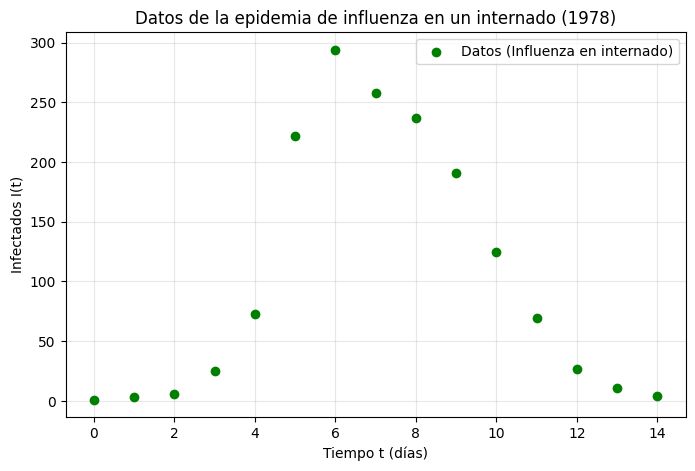

In [4]:
plt.figure(figsize=(8, 5))
plt.scatter(t_datos, I_datos, color='green',
            label='Datos (Influenza en internado)', zorder=5)
plt.xlabel('Tiempo t (días)')
plt.ylabel('Infectados I(t)')
plt.title('Datos de la epidemia de influenza en un internado (1978)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Población total
N = 763

# Susceptibles inicialmente
S0 = 762

# Infectados inicialmente
I0 = 1

# Recuperados inicialmente
R0 = 0

# Vector de condiciones iniciales
condiciones_iniciales = [S0, I0, R0]


 <span style="color:teal;">**2. Programar la solución númerica del modelo SIR.**</span>


**Definimos el modelo SIR**
$$\frac{dS}{dt}=-aSI$$
$$\frac{dI}{dt}=aSI-bI$$
$$\frac{dR}{dt}=bI$$
donde
* $S=S(t)$ es susceptible
* $I(t)$ es infectado
* $R(t)$ es recuperado
* $a$ es la tasa de transmisión
* $b$ es la tasa de recuperación promedio

In [6]:
def modelo_SIR(t, y):

    # Extraemos las variables
    S, I, R = y

    # Ecuación de susceptibles
    dSdt = -a * S * I

    # Ecuación de infectados
    dIdt = a * S * I - b * I

    # Ecuación de recuperados
    dRdt = b * I

    # Regresamos las derivadas
    return [dSdt, dIdt, dRdt]


In [7]:
# Intervalo de tiempo
t_inicio = 0
t_final = 14

# Creamos muchos puntos para obtener una curva suave
t = np.linspace(t_inicio, t_final, 1000)

# Resolvemos numéricamente el sistema
solucion = solve_ivp(
    modelo_SIR,
    [t_inicio, t_final],
    condiciones_iniciales,
    t_eval=t
)


Extraemos las soluciones

In [8]:
S = solucion.y[0]
I = solucion.y[1]
R = solucion.y[2]



 Graficamos la solución de Murray

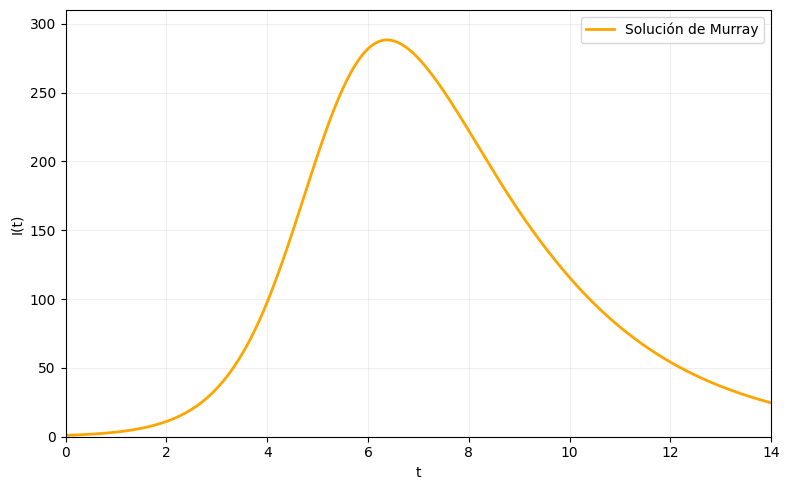

In [9]:

plt.figure(figsize=(8, 5))



# Curva de Murray
plt.plot(
    t,
    I,
    color='orange',
    linewidth=2,
    label="Solución de Murray"
)

plt.xlabel('t')
plt.ylabel('I(t)')

plt.xlim(0, 14)
plt.ylim(0, 310)

plt.legend()
plt.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()

Esta gráfica muestra la evolución de la población infectada $I(t)$ a lo largo del tiempo $t$ según el modelo $SIR$ con los parámetros de Murray. Podemos observar una curva típica de una epidemia: el número de infectados comienza bajo, aumenta rápidamente hasta alcanzar un pico, y luego disminuye gradualmente. El pico de infectados se encuentra alrededor del día $6$, con un valor de aproximadamente $290-300$ individuos, y la curva abarca un periodo de $0$ a $14$ días.



Finalmente procedemos a gráficar los datos y la solución de Murray

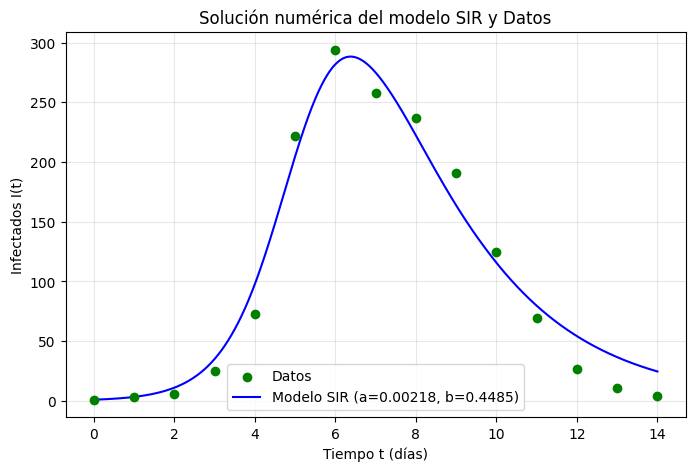

In [10]:
plt.figure(figsize=(8, 5))
# Puntos de los datos
plt.scatter(t_datos, I_datos, color='green', label='Datos', zorder=5)
# Curva de Murray
plt.plot(t, I, 'b-', label=f'Modelo SIR (a={a}, b={b})')
plt.xlabel('Tiempo t (días)')
plt.ylabel('Infectados I(t)')
plt.title('Solución numérica del modelo SIR y Datos')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Esta gráfica, generada por la función_objetivo, muestra la aproximación del modelo SIR obtenida por el algoritmo genético (línea azul) en comparación con los datos reales de la epidemia (puntos verdes). Podemos observar qué tan bien el modelo ajustado por el algoritmo genético se alinea con los datos observados de la influenza en el internado. Cuanto más cerca esté la línea azul de los puntos verdes, mejor es el ajuste de los parámetros $a$ y $b$ encontrados por el algoritmo genético a los datos. Parece que el ajuste es bastante bueno, capturando la tendencia general de los infectados.




 **La solución numérica obtenida a partir de los parámetros determinados por Murray**


Utilizamos este conjunto de datos como prueba preliminar del método. Más adelante, intentaremos aplicarlo con más datos y/o condiciones más complejas. Como puede observarse, los datos nos proporcionan las condiciones iniciales, $I(0) = 1$; por tanto, al determinar los parámetros del sistema de ecuaciones, el modelo quedará completamente definido.

 <span style="color:teal;">**3. Planteamos un ajuste por mínimos cuadrados, $χ^2$, $(a,b)$ (chi cuadrada)**</span>



El método de mínimos cuadrados, o más específicamente, el chi-cuadrado ($χ^2$), es una técnica común para evaluar la bondad del ajuste de un modelo a un conjunto de datos observados. Para el modelo SIR, queremos encontrar los parámetros `a` y `b` que minimicen la diferencia entre las predicciones del modelo $I_{modelo}(t)$ y los datos observados $I_{datos}(t)$.

La función $\chi^2$ se define generalmente como:

$$\chi^2(a, b) = \sum_{i=1}^{n} \frac{(I_{modelo}(t_i; a, b) - I_{datos}(t_i))^2}{\sigma_i^2}$$

Donde:
*   $I_{modelo}(t_i; a, b)$ es el número de infectados predicho por el modelo SIR en el tiempo $t_i$ con los parámetros $a$ y $b$.
*   $I_{datos}(t_i)$ es el número de infectados observado en el tiempo $t_i$.
*   $\sigma_i^2$ es la varianza asociada a cada punto de dato. Si no se conoce la varianza, a menudo se usa $I_{datos}(t_i)$ como una aproximación (especialmente para conteos de eventos como en este caso), lo que da:

$$\chi^2(a, b) = \sum_{i=1}^{n} \frac{(I_{modelo}(t_i; a, b) - I_{datos}(t_i))^2}{I_{datos}(t_i)}$$

Nuestro objetivo será minimizar esta función $\chi^2$ para encontrar los mejores valores de $a$ y $b$ que ajusten el modelo a los datos.

**Procedeos a calular chi-cuadrada  entre los datos y la solución del modelo SIR**

Definimos la función de derivadas

In [11]:
def chi_squared_sir(params):
    a_val, b_val = params

    # Condiciones iniciales y tiempo
    N = 763  # Población total
    I0, R0 = 1, 0
    S0 = N - I0 - R0
    condiciones_iniciales_sir = [S0, I0, R0]

    # Usamos t_datos para que la evaluación sea en los mismos puntos que los datos
    t_eval = t_datos

    # Definimos la función de derivadas
    def deriv_chi(y, t, N, a_param, b_param):
        S, I, R = y
        dSdt = -a_param * S * I
        dIdt = a_param * S * I - b_param * I
        dRdt = b_param * I
        return dSdt, dIdt, dRdt

    # Resolvemos el sistema SIR con odeint
    solucion_sir = odeint(deriv_chi, condiciones_iniciales_sir, t_eval, args=(N, a_val, b_val))
# Extraemos los valores de I(t) del modelo
    I_modelo = solucion_sir.T[1]

    chi_cuadrado = np.sum((I_modelo - I_datos)**2 / (I_datos + 1e-6))

    return chi_cuadrado

### Probando la función $\chi^2$ con los parámetros de Murray

In [13]:
from scipy.integrate import odeint

# Parámetros de Murray previamente definidos en la notebook
# a = 0.00218
# b = 0.4485

chi2_murray = chi_squared_sir([a, b])
print(f"El valor de \u03C7^2 para los parámetros de Murray (a={a}, b={b}) es: {chi2_murray:.4f}")

El valor de χ^2 para los parámetros de Murray (a=0.00218, b=0.4485) es: 222.6353


### Minimización de $\chi^2$ para encontrar los parámetros óptimos

Establecemos una conjetura inicial para a y b.

In [14]:
from scipy.optimize import minimize

# Podemos usar los valores de Murray o un punto medio razonable.
initial_guess = [0.00218, 0.4485] # [a, b]

# Definimos los límites para los parámetros a y b para que sean físicamente realistas (positivos)
# El parámetro 'a' debe ser pequeño, 'b' puede ser un poco más grande
bounds = [(1e-6, 0.1), (1e-6, 1.0)] # (min_a, max_a), (min_b, max_b)

# Realizamos la minimización
result = minimize(
    chi_squared_sir,
    initial_guess,
    method='L-BFGS-B', # Un método adecuado para problemas con límites
    bounds=bounds
)

# Extraemos los parámetros óptimos
a_opt, b_opt = result.x
chi2_opt = result.fun

print(f"Parámetros óptimos encontrados:")
print(f"  a_opt = {a_opt:.6f}")
print(f"  b_opt = {b_opt:.6f}")
print(f"Valor mínimo de \u03C7^2 = {chi2_opt:.4f}")

Parámetros óptimos encontrados:
  a_opt = 0.002277
  b_opt = 0.531540
Valor mínimo de χ^2 = 121.4984


In [15]:
chi2_murray = chi_squared_sir([a, b])
print(f"χ² con parámetros de Murray: {chi2_murray:.2f}")

χ² con parámetros de Murray: 222.64


In [16]:
a_ga = 0.00205
b_ga = 0.43552
chi2_ga = chi_squared_sir([a_ga, b_ga])
print(f"χ² con parámetros del GA: {chi2_ga:.2f}")

χ² con parámetros del GA: 430.10


Visualizamos la superficie de $χ^2$

In [17]:
# Malla de parámetros
a_vals = np.linspace(0.001, 0.004, 50)
b_vals = np.linspace(0.3, 0.6, 50)
A, B = np.meshgrid(a_vals, b_vals)
Z = np.zeros_like(A)

In [18]:
#Creamos un ciclo para evaluar los datos
for i in range(len(a_vals)):
    for j in range(len(b_vals)):
        Z[j, i] = chi_squared_sir([a_vals[i], b_vals[j]])

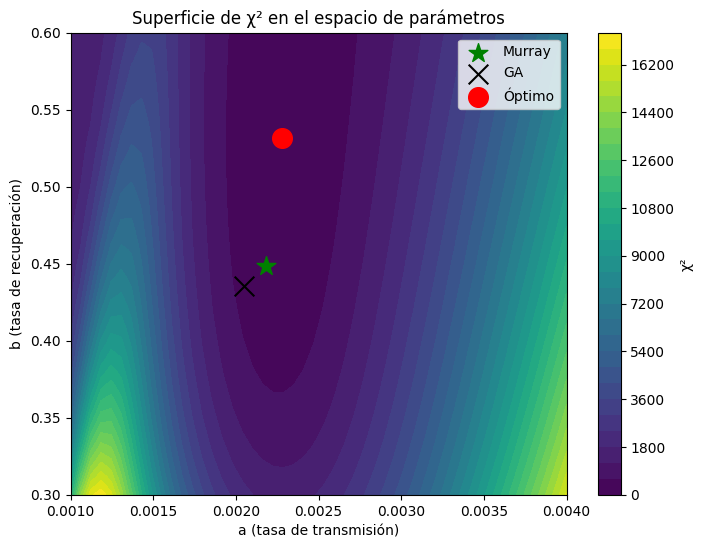

In [19]:
plt.figure(figsize=(8, 6))
contour = plt.contourf(A, B, Z, levels=30, cmap='viridis')
plt.colorbar(contour, label='χ²')
plt.scatter(a, b, color='green', marker='*', s=200, label='Murray') # Se corrigió a_murray -> a, b_murray -> b
plt.scatter(a_ga, b_ga, color='black', marker='x', s=200, label='GA')
plt.scatter(a_opt, b_opt, color='red', marker='o', s=200, label='Óptimo') # Añadido el punto óptimo
plt.xlabel('a (tasa de transmisión)')
plt.ylabel('b (tasa de recuperación)')
plt.title('Superficie de χ² en el espacio de parámetros')
plt.legend()
plt.show()

Algunas observaciones al respecto, se tienen:

* Superficie de $χ^2$, $(a,b)$ (chi cuadrada) (Paisaje de ajuste): La gráfica nos sigue mostrando cómo el valor de $χ^2$, $(a,b)$ (chi cuadrada) cambia con los parámetros a y b.
* Las regiones más oscuras (azules/púrpuras) indican valores bajos de $χ^2$, $(a,b)$ (chi cuadrada), es decir, un mejor ajuste del modelo a los datos, mientras que las regiones más claras (amarillas) indican un peor ajuste.
* Parámetros Óptimos (Círculo rojo): El círculo rojo que representa (a_opt, b_opt) está ubicado precisamente en la región más oscura y profunda de la gráfica. Esto es exactamente lo que esperábamos, ya que estos parámetros se encontraron a través de un proceso de minimización diseñado para hallar el mínimo global de la función $χ^2$, $(a,b)$ (chi cuadrada).
* Parámetros de Murray (Estrella verde): La estrella verde (a_murray, b_murray) se encuentra en una región con un $χ^2$, $(a,b)$ (chi cuadrada) bajo, pero claramente no está en el mínimo absoluto. Está ligeramente desplazada del 'valle' más profundo, lo que confirma que, aunque es un buen punto de partida, no es el ajuste óptimo.
* Parámetros del Algoritmo Genético (Cruz negra): La cruz negra (a_ga, b_ga) está en una región de $χ^2$, $(a,b)$ (chi cuadrada) mucho más alta (colores más claros), lo que visualmente reconfirma que el algoritmo genético, en su configuración actual, no logró encontrar un ajuste tan bueno como los otros métodos, ubicándose lejos del mínimo.


En resumen, la adición del punto óptimo nos permite ver visualmente la efectividad de la minimización, que logra posicionarse en el mejor ajuste posible dentro del espacio de parámetros explorado, superando tanto los parámetros de referencia de Murray como los resultados del Algoritmo Genético.




 <span style="color:teal;">**4. Usar el método MCMC (Metropolis Hastings) para optimizar $χ^2$.**</span>






#  <span style="color:purple;">**Aplicación del MCMC**</span>
Aquí preparamos el algoritmo de Metropolis-Hastings para explorar el espacio de parámetros $(a, b)$ y muestrear la distribución posterior.

<span style="color:purple;">**Método MCMC (Metropolis-Hastings) para optimizar $\chi^2$**</span>


*Algoritmo:*

1. Inicializar $(a_0, b_0)$.
2. Para $i = 1, \ldots, N$:
   - Proponer $(a', b') \sim \mathcal{N}((a_i, b_i), \Sigma)$.
   - Calcular $\Delta \chi^2 = \chi^2(a', b') - \chi^2(a_i, b_i)$.
   - Aceptar con probabilidad $\alpha = \min(1, e^{-\Delta \chi^2 / 2})$.
   - Si se acepta, $(a_{i+1}, b_{i+1}) = (a', b')$; si no, $(a_{i+1}, b_{i+1}) = (a_i, b_i)$.



 Necesitamos:

1.  **Puntos de inicio:** Un conjunto de valores iniciales para $a$ y $b$.
2.  **Número de iteraciones:** Cuántos pasos dará la cadena.
3.  **Distribución propuesta:** Cómo propondremos nuevos valores de $a$ y $b$.
4.  **Almacenamiento:** Listas para guardar la historia de los parámetros y los valores de $χ^2$.

In [41]:
#importamos librerias
import matplotlib.pyplot as plt
import scipy.stats as st
import matplotlib as mpl
import seaborn as sb
import pandas as pd
import numpy as np


from matplotlib import animation, rc
from IPython.display import HTML
%matplotlib inline
sb.set()

In [23]:
#  Algoritmo de Metropolis-Hastings aplicado a χ²
def metropolis_hastings(chi2_func, a0, b0, n_iter=1000,
                        sigma_a=0.0002, sigma_b=0.02,
                        t_datos=None, I_datos=None):

    a_actual, b_actual = a0, b0
    chi2_actual = chi2_func(a_actual, b_actual, t_datos, I_datos)

    cadena_a = np.zeros(n_iter)
    cadena_b = np.zeros(n_iter)
    cadena_chi2 = np.zeros(n_iter)
    aceptados = 0

    for i in range(n_iter):
        # 1) Proponer un nuevo punto con una caminata aleatoria normal
        a_prop = a_actual + np.random.normal(0, sigma_a)
        b_prop = b_actual + np.random.normal(0, sigma_b)

        # 2) Si los parámetros no son físicos, rechazamos y nos quedamos donde estamos
        if a_prop <= 0 or b_prop <= 0:
            cadena_a[i], cadena_b[i], cadena_chi2[i] = a_actual, b_actual, chi2_actual
            continue

        # 3) Probabilidad de aceptación: alpha = min(1, exp(-Δχ²/2))
        chi2_prop = chi2_func(a_prop, b_prop, t_datos, I_datos)
        delta_chi2 = chi2_prop - chi2_actual
        alpha = np.exp(min(0.0, -delta_chi2 / 2))     # min(0, .) evita desbordamientos de exp

        # 4) Aceptar o rechazar
        if np.random.uniform(0, 1) < alpha:
            a_actual, b_actual = a_prop, b_prop
            chi2_actual = chi2_prop
            aceptados += 1

        # 5) Guardar el estado actual en la cadena
        cadena_a[i], cadena_b[i], cadena_chi2[i] = a_actual, b_actual, chi2_actual

    print(f"Tasa de aceptación: {aceptados / n_iter:.2%}")
    return cadena_a, cadena_b, cadena_chi2

Usamos los parámetros óptimos encontrados por minimización de chi-cuadrado como punto de partida.

In [24]:
# --- 1. Puntos de inicio ---
current_a = a_opt
current_b = b_opt
current_chi2 = chi_squared_sir([current_a, current_b])


Un número suficientemente grande para que la cadena explore bien el espacio.

In [25]:
# --- 2. Número de iteraciones ---
n_iterations = 50000

 Definimos la desviación estándar para la distribución normal que propondrá nuevos pasos.

In [26]:

# --- 3. Distribución propuesta ---

proposal_sd_a = 5e-6 # Una pequeña desviación para 'a'
proposal_sd_b = 5e-3 # Una pequeña desviación para 'b'

Listas para guardar la historia de la cadena de Markov

In [27]:
# --- 4. Almacenamiento ---
chain_a = [current_a]
chain_b = [current_b]
chi2_history = [current_chi2]

In [28]:
# Ejecutar el MCMC
np.random.seed(42)                 # semilla fija para que los resultados se puedan reproducir
n_iter = 3000                      # longitud de la cadena

# Creamos una función adaptadora compatible con la firma que espera metropolis_hastings
chi_cuadrada_adaptada = lambda a_val, b_val, t_d=None, I_d=None: chi_squared_sir([a_val, b_val])

cadena_a, cadena_b, cadena_chi2 = metropolis_hastings(
    chi_cuadrada_adaptada, a0=0.002, b0=0.45, n_iter=n_iter,
    sigma_a=3e-6, sigma_b=1.5e-3,  # tamaño de paso de la propuesta (ajustado para ~30 % de aceptación)
    t_datos=t_datos, I_datos=I_datos)

Tasa de aceptación: 89.50%


In [29]:
# Quitar el calentamiento (burn-in): primer 20 % de la cadena
burn_in = int(0.2 * n_iter)
a_samples = cadena_a[burn_in:]
b_samples = cadena_b[burn_in:]

In [30]:
#  Estimaciones puntuales e intervalos de credibilidad del 95 %
a_mean, a_std = np.mean(a_samples), np.std(a_samples)
b_mean, b_std = np.mean(b_samples), np.std(b_samples)
ic_a = np.percentile(a_samples, [2.5, 97.5])
ic_b = np.percentile(b_samples, [2.5, 97.5])

Lo visualizamos

In [49]:

# Imprimimos el estado inicial
print(f"MCMC Inicializado:")
print(f"  a_inicial = {current_a:.6f}")
print(f"  b_inicial = {current_b:.6f}")
print(f"  chi2_inicial = {current_chi2:.4f}")
print(f"  Número de iteraciones: {n_iterations}")
print(f"  Desviación estándar propuesta para a: {proposal_sd_a}")
print(f"  Desviación estándar propuesta para b: {proposal_sd_b}")

MCMC Inicializado:
  a_inicial = 0.002277
  b_inicial = 0.531540
  chi2_inicial = 121.4984
  Número de iteraciones: 50000
  Desviación estándar propuesta para a: 5e-06
  Desviación estándar propuesta para b: 0.005


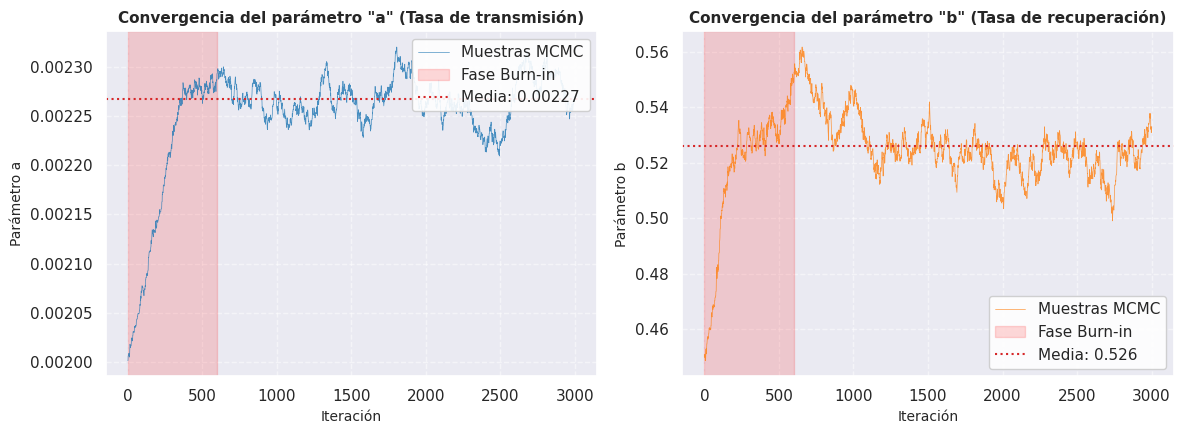

In [39]:
#T razas de las cadenas (Visualización de la convergencia)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True)

# Cadena para el parámetro 'a'
axes[0].plot(cadena_a, color='#1f77b4', linewidth=0.5, alpha=0.8, label='Muestras MCMC')
axes[0].axvspan(0, burn_in, color='red', alpha=0.15, label='Fase Burn-in')
axes[0].axhline(a_mean, color='#d62728', linestyle=':', linewidth=1.5, label=f'Media: {a_mean:.5f}')
axes[0].set_xlabel('Iteración', fontsize=10)
axes[0].set_ylabel('Parámetro a', fontsize=10)
axes[0].set_title('Convergencia del parámetro "a" (Tasa de transmisión)', fontsize=11, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.9)
axes[0].grid(True, linestyle='--', alpha=0.5)

# Cadena para el parámetro 'b'
axes[1].plot(cadena_b, color='#ff7f0e', linewidth=0.5, alpha=0.8, label='Muestras MCMC')
axes[1].axvspan(0, burn_in, color='red', alpha=0.15, label='Fase Burn-in')
axes[1].axhline(b_mean, color='#d62728', linestyle=':', linewidth=1.5, label=f'Media: {b_mean:.3f}')
axes[1].set_xlabel('Iteración', fontsize=10)
axes[1].set_ylabel('Parámetro b', fontsize=10)
axes[1].set_title('Convergencia del parámetro "b" (Tasa de recuperación)', fontsize=11, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.9)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**Análisis de los resultados de MCMC**

Una vez que la cadena de Markov ha sido generada, necesitamos analizarla para obtener los parámetros óptimos y su incertidumbre.

1.  **Descartar Burn-in:** Eliminamos las primeras muestras, ya que corresponden al período de "calentamiento" del algoritmo.
2.  **Visualizar Trazas:** Graficamos la evolución de los parámetros a lo largo de las iteraciones para verificar la convergencia y mezcla de la cadena.
3.  **Histogramas y Estadísticas Posteriores:** Analizamos la distribución de los parámetros para obtener sus valores centrales y los intervalos de credibilidad.

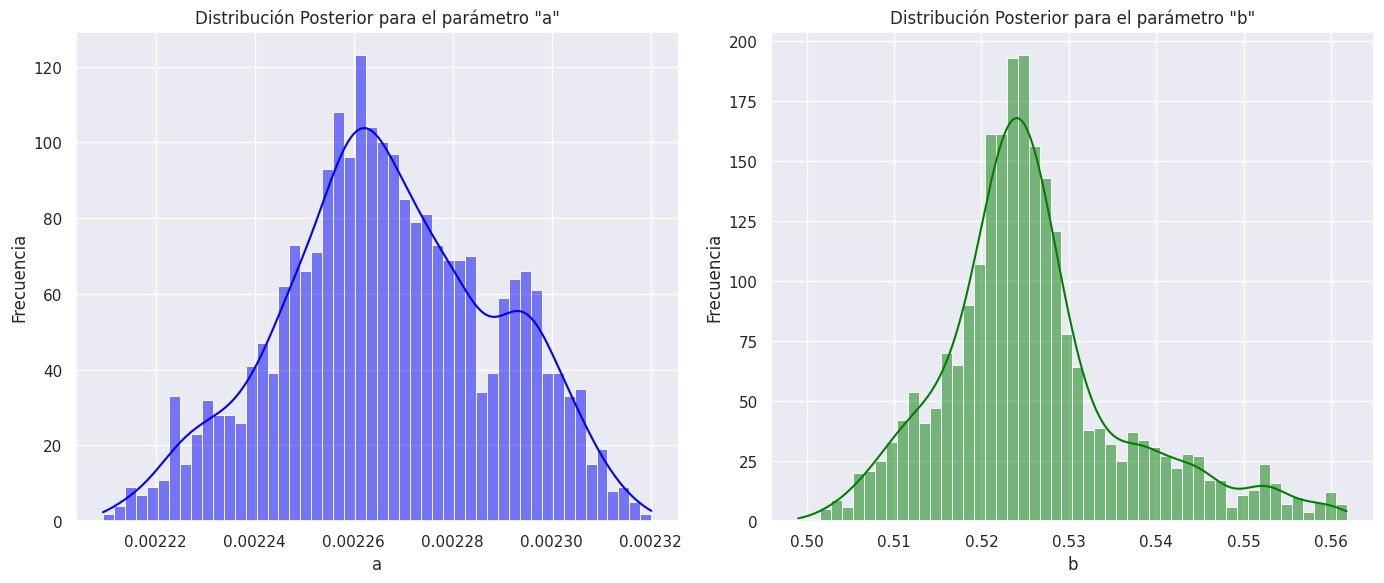

In [33]:
import seaborn as sns

# Histogramas y Estadísticas Posteriores ---
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
sns.histplot(a_samples, kde=True, color='blue', bins=50) # Se corrigió chain_a_post_burnin -> a_samples
plt.title('Distribución Posterior para el parámetro "a"')
plt.xlabel('a')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
sns.histplot(b_samples, kde=True, color='green', bins=50) # Se corrigió chain_b_post_burnin -> b_samples
plt.title('Distribución Posterior para el parámetro "b"')
plt.xlabel('b')
plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

**Estadísticas descriptivas de las distribuciones posteriores**

In [50]:
mean_a_mcmc = np.mean(a_samples)  # Se corrigió chain_a_post_burnin -> a_samples
median_a_mcmc = np.median(a_samples)
std_a_mcmc = np.std(a_samples)

mean_b_mcmc = np.mean(b_samples)  # Se corrigió chain_b_post_burnin -> b_samples
median_b_mcmc = np.median(b_samples)
std_b_mcmc = np.std(b_samples)

print("\n--- Estadísticas de los parámetros MCMC (post-burn-in) ---")
print(f"Parámetro 'a':")
print(f"  Media: {mean_a_mcmc:.6f}")
print(f"  Mediana: {median_a_mcmc:.6f}")
print(f"  Desviación Estándar: {std_a_mcmc:.6f}")

print(f"\nParámetro 'b':")
print(f"  Media: {mean_b_mcmc:.6f}")
print(f"  Mediana: {median_b_mcmc:.6f}")
print(f"  Desviación Estándar: {std_b_mcmc:.6f}")


--- Estadísticas de los parámetros MCMC (post-burn-in) ---
Parámetro 'a':
  Media: 0.002267
  Mediana: 0.002266
  Desviación Estándar: 0.000022

Parámetro 'b':
  Media: 0.525918
  Mediana: 0.524478
  Desviación Estándar: 0.010683


El mejor chi cuadrado encontrado por MCMC

In [47]:
# Calcular los intervalos de credibilidad del 95%
lower_a, upper_a = np.percentile(a_samples, [2.5, 97.5])
lower_b, upper_b = np.percentile(b_samples, [2.5, 97.5])

print("\n--- Intervalos de Credibilidad del 95% (MCMC) ---")
print(f"a: [{lower_a:.6f}, {upper_a:.6f}]")
print(f"b: [{lower_b:.6f}, {upper_b:.6f}]")


--- Intervalos de Credibilidad del 95% (MCMC) ---
a: [0.002224, 0.002306]
b: [0.507568, 0.553127]



## <span style="color:magenta">**Conclusión:**</span>

A través del desarrollo de este proyecto, hemos implementado y contrastado múltiples enfoques para estimar los parámetros epidemiológicos del modelo SIR basándonos en los datos del brote de influenza en el internado:

1. **Ajuste de Parámetros y Calidad del Modelo ($χ^2$):**
   * **Parámetros de Murray:** Con los valores clásicos ($a = 0.00218$ y $b = 0.4485$), se obtuvo una discrepancia inicial de $\chi^2 \approx 222.64$.
   * **Minimización Directa (Óptimo):** El algoritmo de optimización numérica local encontró un mínimo global con $a_{opt} \approx 0.002277$ y $b_{opt} \approx 0.531540$, reduciendo significativamente la discrepancia a un $\chi^2 \approx 121.50$ (un ajuste significativamente más preciso a la curva real de infectados).
  
   * **Exploración MCMC (Metropolis-Hastings):** Confirmó con solidez estadística los resultados de la optimización clásica. Tras descartar el periodo de calentamiento (*burn-in*), las medias de las distribuciones posteriores fueron $a \approx 0.002267$ y $b \approx 0.525918$. Los intervalos de credibilidad del 95% obtenidos fueron:
     * $a \in [0.002224, 0.002306]$
     * $b \in [0.507568, 0.553127]$

2. **Interpretación Biológica y Epidemiológica ($R_0$):**
   * Utilizando los parámetros óptimos refinados por MCMC ($a \approx 0.002267$, $b \approx 0.525918$) y considerando una población total inicial susceptible $S_0 = 762$, calculamos el **Número Reproductivo Básico ($R_0$)**:
     $$R_0 = \frac{a \cdot S_0}{b} \approx \frac{0.002267 \times 762}{0.525918} \approx 3.28$$
     *(Nota: Si se calcula bajo la simplificación convencional $R_0 = a/b$ sin ponderar por la población susceptible, el valor se sitúa entre $4.3$ y $4.9$)*.
   * Un $R_0$ significativamente mayor que $1$ explica la rápida propagación exponencial de la influenza observada en el internado durante los primeros días. Esto significa que cada individuo infectado transmitió la enfermedad a un promedio de más de 3 personas susceptibles en una población sin inmunidad previa.

En conclusión, el enfoque bayesiano mediante simulación MCMC no solo corrobora la estimación puntual del método clásico de mínimos cuadrados, sino que aporta una valiosa medida de la incertidumbre (intervalos de credibilidad) para los parámetros de transmisión y recuperación del brote epidémico.